# Introduction to Regression Techniques

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import make_friedman1, make_regression
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler, PolynomialFeatures, StandardScaler

FIG_DIR = Path("figures_regression")
FIG_DIR.mkdir(exist_ok=True)
for old_png in FIG_DIR.glob("*.png"):
    old_png.unlink()

plt.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 220,
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

RNG = np.random.default_rng(42)

def savefig(name):
    plt.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")
    plt.show()

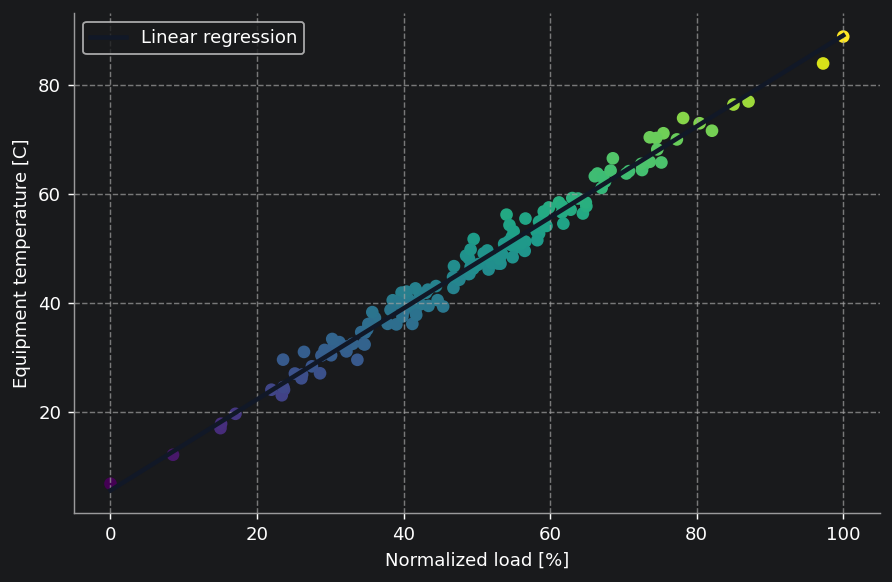

In [2]:
# Figure 1: numeric target in regression.
X, y_raw = make_regression(
    n_samples=150,
    n_features=1,
    noise=18.0,
    random_state=12,
)
X = MinMaxScaler().fit_transform(X) * 100
y = 0.50 * X.ravel() + 22 + (y_raw - y_raw.mean()) / y_raw.std() * 6

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=1
)

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

x_grid = np.linspace(0, 100, 300).reshape(-1, 1)
y_grid = linear_model.predict(x_grid)

plt.figure(figsize=(8, 5))
plt.scatter(X, y, c=y)
plt.plot(x_grid[:, 0], y_grid, color="#111827", lw=2.5, label="Linear regression")
plt.xlabel("Normalized load [%]")
plt.ylabel("Equipment temperature [C]")
plt.grid(True, linestyle="--", linewidth=0.8, alpha=0.7)
plt.legend(frameon=True)
savefig("numeric_regression")
plt.show()

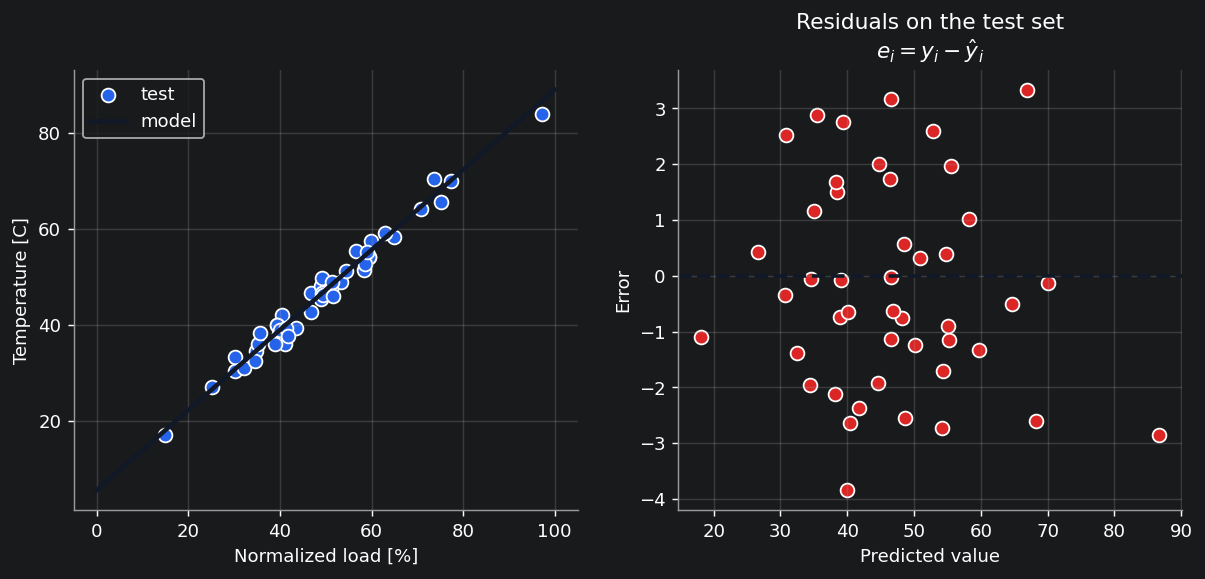

In [3]:
# Figure 2: residuals as prediction errors.
y_pred_test = linear_model.predict(X_test)
residuals = y_test - y_pred_test

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))

axes[0].scatter(X_test[:, 0], y_test, c="#2563eb", edgecolor="white", s=58, label="test")
axes[0].plot(x_grid[:, 0], y_grid, color="#111827", lw=2.5, label="model")
axes[0].set_xlabel("Normalized load [%]")
axes[0].set_ylabel("Temperature [C]")
axes[0].legend(frameon=True)

axes[1].scatter(y_pred_test, residuals, c="#dc2626", edgecolor="white", s=58)
axes[1].axhline(0, color="#111827", lw=2, ls="--")
axes[1].set_title("Residuals on the test set\n" + r"$e_i = y_i - \hat{y}_i$")
axes[1].set_xlabel("Predicted value")
axes[1].set_ylabel("Error")

savefig("regression_residuals")

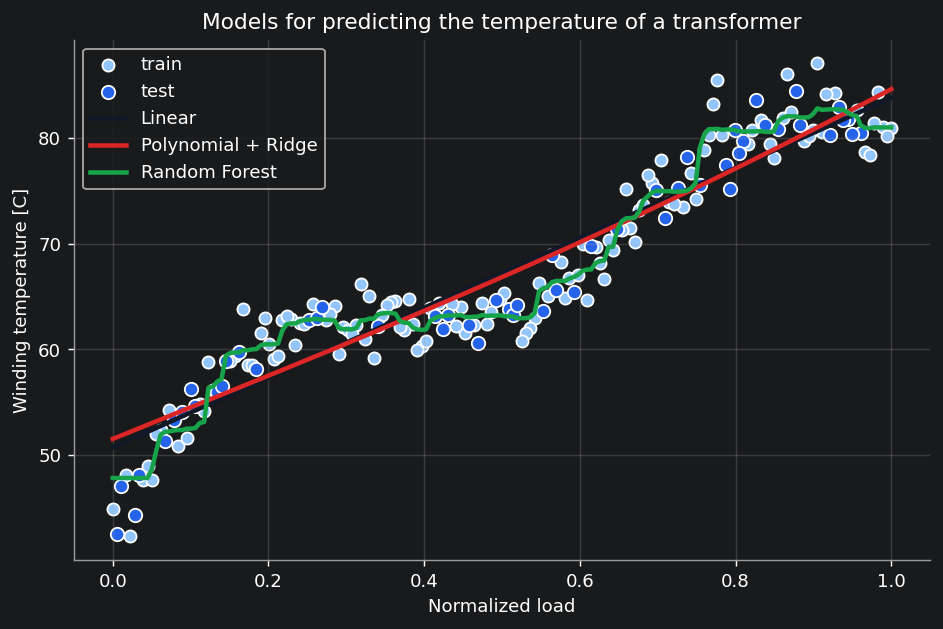

In [4]:
# Figure 4: linear and nonlinear models for predicting the temperature of a transformer.
x = np.linspace(0, 1, 180).reshape(-1, 1)

# Didactic interpretation:
# x = normalized transformer load
# y = winding temperature [C]
y_curve = 55 + 28 * x.ravel() - 30 * (x.ravel() - 0.60) ** 2 + 5 * np.sin(9 * x.ravel())
y_obs = y_curve + 1.3*RNG.normal(0, 1.7, size=x.shape[0])

X_train_curve, X_test_curve, y_train_curve, y_test_curve = train_test_split(
    x, y_obs, test_size=0.30, random_state=4
)

curve_models = {
    "Linear": LinearRegression(),
    "Polynomial + Ridge": make_pipeline(
        PolynomialFeatures(degree=4, include_bias=False),
        StandardScaler(),
        Ridge(alpha=0.7),
    ),
    "Random Forest": RandomForestRegressor(n_estimators=120, min_samples_leaf=4, random_state=4),
}

fig, ax = plt.subplots(figsize=(8.5, 5.2))
ax.scatter(X_train_curve[:, 0], y_train_curve, c="#93c5fd", edgecolor="white", s=45, label="train")
ax.scatter(X_test_curve[:, 0], y_test_curve, c="#2563eb", edgecolor="white", s=55, label="test")

colors = {"Linear": "#111827", "Polynomial + Ridge": "#dc2626", "Random Forest": "#16a34a"}
for name, model in curve_models.items():
    model.fit(X_train_curve, y_train_curve)
    ax.plot(x[:, 0], model.predict(x), lw=2.5, color=colors[name], label=name)

ax.set_title("Models for predicting the temperature of a transformer")
ax.set_xlabel("Normalized load")
ax.set_ylabel("Winding temperature [C]")
ax.legend(frameon=True)
savefig("regression_model_curves")

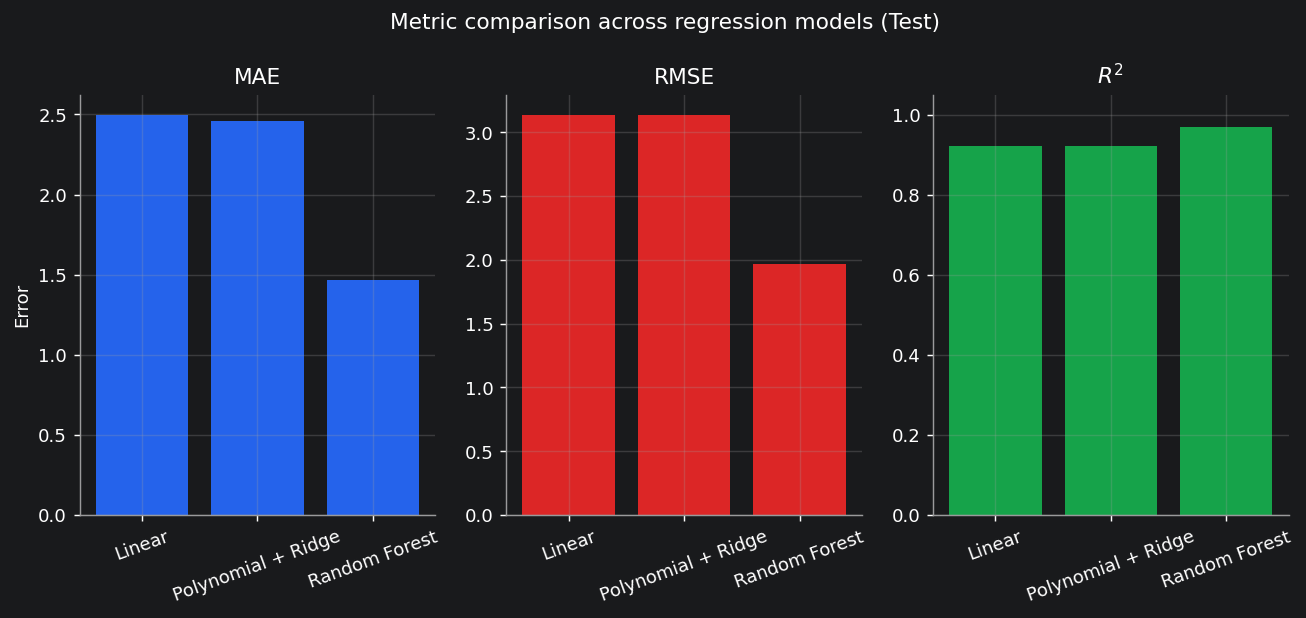

In [5]:
# Figure 5: metric comparison across the regression models studied.
names, mae_values, rmse_values, r2s = [], [], [], []

for name, model in curve_models.items():
    model.fit(X_train_curve, y_train_curve)
    y_pred_curve = model.predict(X_test_curve)

    names.append(name)
    mae_values.append(mean_absolute_error(y_test_curve, y_pred_curve))
    rmse_values.append(root_mean_squared_error(y_test_curve, y_pred_curve))
    r2s.append(r2_score(y_test_curve, y_pred_curve))

fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))

axes[0].bar(names, mae_values, color="#2563eb")
axes[0].set_title("MAE")
axes[0].set_ylabel("Error")
axes[0].tick_params(axis="x", rotation=20)

axes[1].bar(names, rmse_values, color="#dc2626")
axes[1].set_title("RMSE")
axes[1].tick_params(axis="x", rotation=20)

axes[2].bar(names, r2s, color="#16a34a")
axes[2].set_title(r"$R^2$")
axes[2].set_ylim(0, 1.05)
axes[2].tick_params(axis="x", rotation=20)

fig.suptitle("Metric comparison across regression models (Test)", y=1.03)
savefig("regression_model_metrics")

In [6]:
# Minimal regression example with sklearn.
model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print(f"MAE: {mean_absolute_error(y_test, y_pred):.2f}")
print(f"RMSE: {root_mean_squared_error(y_test, y_pred):.2f}")
print(f"R2: {r2_score(y_test, y_pred):.3f}")
print("First predictions:", np.round(y_pred[:8], 2))

MAE: 1.54
RMSE: 1.84
R2: 0.978
First predictions: [34.59 55.24 44.71 55.14 39.31 26.61 38.9  50.18]
